In [22]:

import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.optim import Adam

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error,explained_variance_score

from scipy.stats import pearsonr

from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


Using device: cuda


In [23]:
print('Hello world')

Hello world


In [24]:
def set_seed(seed=42):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False

set_seed(42)

In [25]:
data_df = pd.read_csv("D:\APSirCNTandLSTM\CNT with LSTM\Datasets\CNT_Reinforced Concrete_Final Dataset.csv") # Read the data

data_df.dropna(inplace = True) # Drop missing/null values

print("Original Data Shape: ", data_df.shape)

def is_numeric_row(row):
    try:
        pd.to_numeric(row, errors='raise')
        return True
    except:
        return False
    

numeric_rows = data_df.apply(lambda row: is_numeric_row(row), axis=1)
data_df = data_df[numeric_rows]

print("Data Shape (rows, cols): ", data_df.shape) # Print data shape
data_df # Print/visualize the first 5 rows of the data

Original Data Shape:  (295, 7)
Data Shape (rows, cols):  (295, 7)


,Cement (kg/m³),w/c,Coarse aggregate (kg/m³),Fine aggregate (kg/m³),Curing (days),CNT (%),Compressive strength(MPa)
0,360.0,0.50,950.0,745.0,28,0.00,39.500
1,320.0,0.56,898.0,782.0,28,0.00,40.000
2,328.5,0.68,533.7,625.1,28,0.00,40.000
3,360.0,0.50,898.0,797.0,28,0.00,40.000
4,320.0,0.56,845.0,834.0,28,0.00,40.300
...,...,...,...,...,...,...,...
290,400.0,0.45,987.0,780.0,28,0.05,64.000
291,450.0,0.35,1006.0,768.0,28,0.05,84.900
292,525.0,0.45,0.0,1580.0,28,0.00,29.875
293,525.0,0.45,0.0,1580.0,28,0.06,38.750


In [26]:
#Converting non-numeric columns to numeric, if any. This will convert non-numeric values to NaN, which will be dropped later.

for column in data_df.columns:
    data_df[column] = pd.to_numeric(data_df[column], errors='coerce')

In [27]:
data_df.head()
#data_df.shape # Print data shape after conversion to numeric

,Cement (kg/m³),w/c,Coarse aggregate (kg/m³),Fine aggregate (kg/m³),Curing (days),CNT (%),Compressive strength(MPa)
0,360.0,0.50,950.0,745.0,28,0.0,39.5
1,320.0,0.56,898.0,782.0,28,0.0,40.0
2,328.5,0.68,533.7,625.1,28,0.0,40.0
3,360.0,0.50,898.0,797.0,28,0.0,40.0
4,320.0,0.56,845.0,834.0,28,0.0,40.3


In [28]:
target_column = "Compressive strength(MPa)"

# Check data types
print("Data types:")
print(data_df.dtypes)
print("\n" + "="*50 + "\n")

# Check if target column has issues
print(f"Target column '{target_column}' unique values (first 10):")
print(data_df[target_column].unique()[:10])
print(f"\nTarget column type: {data_df[target_column].dtype}")

# Check for any remaining object columns
object_cols = data_df.select_dtypes(include=['object']).columns.tolist()
print(f"\nObject (string) columns: {object_cols}")

Data types:
Cement (kg/m³)               float64
w/c                          float64
Coarse aggregate (kg/m³)     float64
Fine aggregate (kg/m³)       float64
Curing (days)                  int64
CNT (%)                      float64
Compressive strength(MPa)    float64
dtype: object


Target column 'Compressive strength(MPa)' unique values (first 10):
[39.5 40.  40.3 40.8 41.  41.1 41.3 41.5 41.8 42. ]

Target column type: float64

Object (string) columns: []


In [30]:
# Prepare Input and Output

X = np.array(data_df.iloc[:, :-1])
Y = np.array(data_df.iloc[:, -1])

print("Input Shape:", X.shape)
print("Output Shape:", Y.shape)


Input Shape: (295, 6)
Output Shape: (295,)


In [31]:
X, Y

(array([[3.600e+02, 5.000e-01, 9.500e+02, 7.450e+02, 2.800e+01, 0.000e+00],
        [3.200e+02, 5.600e-01, 8.980e+02, 7.820e+02, 2.800e+01, 0.000e+00],
        [3.285e+02, 6.800e-01, 5.337e+02, 6.251e+02, 2.800e+01, 0.000e+00],
        ...,
        [5.250e+02, 4.500e-01, 0.000e+00, 1.580e+03, 2.800e+01, 0.000e+00],
        [5.250e+02, 4.500e-01, 0.000e+00, 1.580e+03, 2.800e+01, 6.000e-02],
        [5.250e+02, 4.500e-01, 0.000e+00, 1.580e+03, 2.800e+01, 1.200e-01]]),
 array([39.5  , 40.   , 40.   , 40.   , 40.3  , 40.8  , 40.8  , 41.   ,
        41.1  , 41.3  , 41.3  , 41.5  , 41.5  , 41.5  , 41.5  , 41.8  ,
        42.   , 42.1  , 42.4  , 42.5  , 43.   , 43.2  , 43.3  , 43.5  ,
        43.6  , 43.8  , 44.   , 44.5  , 45.   , 45.   , 45.1  , 45.7  ,
        46.   , 46.   , 47.1  , 47.7  , 50.   , 36.8  , 43.1  , 38.6  ,
        47.2  , 45.1  , 49.6  , 47.4  , 54.   , 50.1  , 37.8  , 44.1  ,
        40.9  , 47.5  , 45.3  , 42.5  , 52.   , 48.7  , 46.6  , 54.5  ,
        53.1  , 49.2  , 4

In [32]:

# 80 : 20 Split

X_train_us, X_test_us, y_train, y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42
)


print("Training X:", X_train_us.shape)
print("Testing X:", X_test_us.shape)

print("Training y:", y_train.shape)
print("Testing y:", y_test.shape)


print("Training set is: ", X_train_us.shape[0], " rows which is ", round(X_train_us.shape[0]/data_df.shape[0],4)*100, "%") # Print training shape
print("Testing set is: ",X_test_us.shape[0], " rows which is ", round(X_test_us.shape[0]/data_df.shape[0],4)*100, "%") # Print testing shape


Training X: (236, 6)
Testing X: (59, 6)
Training y: (236,)
Testing y: (59,)
Training set is:  236  rows which is  80.0 %
Testing set is:  59  rows which is  20.0 %


In [33]:
# Reshape for LSTM
# Shape: (batch, sequence_length, input_size)

# Standardization

scaler_X = StandardScaler()

X_train = scaler_X.fit_transform(X_train_us)
X_test = scaler_X.transform(X_test_us)

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("LSTM Training Shape X:", X_train.shape)
print("LSTM testing Shape X:", X_test.shape)
print("**********************************")
print("LSTM Training Shape y:", y_train.shape)
print("LSTM testing Shape y:", y_test.shape)

y_train

LSTM Training Shape X: (236, 6, 1)
LSTM testing Shape X: (59, 6, 1)
**********************************
LSTM Training Shape y: (236,)
LSTM testing Shape y: (59,)


array([46.6  , 39.5  , 42.1  , 45.3  , 20.48 , 59.5  , 48.2  , 54.1  ,
       51.2  , 40.7  , 54.8  , 62.6  , 50.4  , 42.5  , 50.4  , 39.6  ,
       57.6  , 36.6  , 41.8  , 41.3  , 56.3  , 44.9  , 58.5  , 36.8  ,
       42.   , 29.875, 52.9  , 47.5  , 47.9  , 50.7  , 51.3  , 47.3  ,
       55.5  , 43.5  , 54.75 , 58.3  , 42.4  , 53.1  , 50.9  , 51.1  ,
       40.9  , 29.51 , 47.5  , 52.6  , 48.5  , 16.74 , 34.2  , 54.5  ,
       25.41 , 49.6  , 34.08 , 43.1  , 31.6  , 57.5  , 49.2  , 52.9  ,
       51.3  , 43.3  , 47.5  , 58.7  , 51.71 , 56.5  , 45.7  , 51.2  ,
       57.5  , 44.   , 14.7  , 32.64 , 42.63 , 54.7  , 54.5  , 45.1  ,
       40.   , 44.5  , 29.5  , 57.4  , 57.8  , 48.   , 52.7  , 50.5  ,
       46.2  , 45.   , 48.1  , 27.34 , 46.9  , 37.69 , 53.1  , 58.16 ,
       59.1  , 40.03 , 42.7  , 64.   , 51.3  , 36.67 , 41.5  , 47.7  ,
       45.   , 60.2  , 55.6  , 36.8  , 23.4  , 42.5  , 43.5  , 36.5  ,
       23.81 , 45.1  , 51.3  , 32.76 , 51.9  , 44.   , 46.2  , 55.3  ,
      

In [34]:

class ConcreteDataset(Dataset):

    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


In [35]:
g = torch.Generator()

g.manual_seed(42)


training_data = ConcreteDataset(X_train, y_train)
testing_data = ConcreteDataset(X_test, y_test)

BATCH_SIZE = 32

train_dataloader = DataLoader(training_data, batch_size=BATCH_SIZE, shuffle=True,  generator=g)
testing_dataloader = DataLoader(testing_data, batch_size=BATCH_SIZE, shuffle=False,  generator=g)


LSTM MODEL

In [36]:

class LSTMRegressor(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.05,
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),
            
            nn.Linear(512, 512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),

            nn.Linear(256, 256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),

            nn.Linear(256, 1)
        )


    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))

        #out = out[:, -1, :]   # Last timestep
        out = torch.mean(out, dim=1)

        out = self.fc(out)

        return out


In [37]:
input_size = 1
hidden_size = 1028
num_layers = 2

num_classes = 1

model = LSTMRegressor(input_size, hidden_size, num_layers).to(device)

print(model)


LSTMRegressor(
  (lstm): LSTM(1, 1028, num_layers=2, batch_first=True, dropout=0.05)
  (fc): Sequential(
    (0): Linear(in_features=1028, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.1)
    (2): Dropout(p=0.05, inplace=False)
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.1)
    (5): Dropout(p=0.05, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): LeakyReLU(negative_slope=0.1)
    (8): Dropout(p=0.05, inplace=False)
    (9): Linear(in_features=256, out_features=256, bias=True)
    (10): LeakyReLU(negative_slope=0.1)
    (11): Dropout(p=0.05, inplace=False)
    (12): Linear(in_features=256, out_features=1, bias=True)
  )
)


In [38]:
LR = 1e-3

criterion = nn.MSELoss()
optimizer = Adam(model.parameters(), lr=LR)


In [39]:
EPOCHS = 1500

total_loss_train_plot = []

for epoch in range(EPOCHS):

    model.train()
    total_loss_train = 0

    for inputs, labels in train_dataloader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(inputs).squeeze(1)

        loss = criterion(predictions, labels)

        loss.backward()

        optimizer.step()

        total_loss_train += loss.item()

    avg_train_loss = total_loss_train / len(train_dataloader)

    
    total_loss_train_plot.append(avg_train_loss)
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS}")
        print(f"Train Loss: {avg_train_loss:.4f}")


Epoch 10/1500
Train Loss: 91.3068
Epoch 20/1500
Train Loss: 103.5632
Epoch 30/1500
Train Loss: 93.4722
Epoch 40/1500
Train Loss: 103.6661
Epoch 50/1500
Train Loss: 68.6941
Epoch 60/1500
Train Loss: 66.1110
Epoch 70/1500
Train Loss: 54.3482
Epoch 80/1500
Train Loss: 54.8856
Epoch 90/1500
Train Loss: 63.0696
Epoch 100/1500
Train Loss: 56.0455
Epoch 110/1500
Train Loss: 66.6610
Epoch 120/1500
Train Loss: 60.3424
Epoch 130/1500
Train Loss: 68.6424
Epoch 140/1500
Train Loss: 67.7036
Epoch 150/1500
Train Loss: 56.0865
Epoch 160/1500
Train Loss: 59.4130
Epoch 170/1500
Train Loss: 58.9260
Epoch 180/1500
Train Loss: 51.4686
Epoch 190/1500
Train Loss: 57.0274
Epoch 200/1500
Train Loss: 47.2347
Epoch 210/1500
Train Loss: 51.1654
Epoch 220/1500
Train Loss: 61.9947
Epoch 230/1500
Train Loss: 55.8000
Epoch 240/1500
Train Loss: 57.0784
Epoch 250/1500
Train Loss: 48.8999
Epoch 260/1500
Train Loss: 53.0676
Epoch 270/1500
Train Loss: 63.9446
Epoch 280/1500
Train Loss: 51.5504
Epoch 290/1500
Train Loss: 

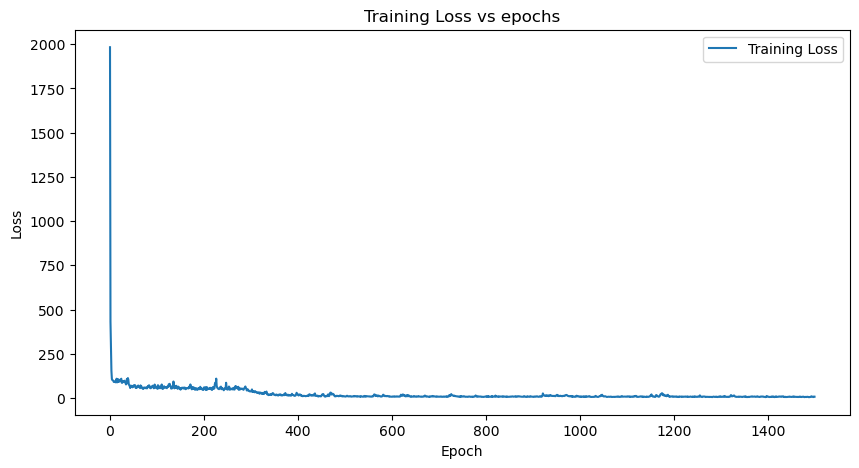

In [40]:
# Loss Plot

plt.figure(figsize=(10,5))

plt.plot(total_loss_train_plot, label='Training Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs epochs")
plt.legend()

plt.show()


In [41]:

def evaluate_model(model, dataloader, device):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for inputs, labels in dataloader:

            inputs = inputs.to(device)

            predictions = model(inputs).squeeze(1)

            y_true.extend(labels.numpy())

            y_pred.extend(
                predictions.cpu().numpy()
            )

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)


    r2 = r2_score(y_true, y_pred)

    mse = mean_squared_error(y_true, y_pred)

    rmse = np.sqrt(mse)

    mae = mean_absolute_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(
        y_true,
        y_pred
    ) * 100

    evs = explained_variance_score(
        y_true,
        y_pred
    )

    pearson_r, _ = pearsonr(
        y_true,
        y_pred
    )

    rrmse = (
        rmse / np.mean(y_true)
    ) * 100


    return {
        "R2 Score": r2,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape,
        "Explained Variance Score": evs,
        "Pearson Correlation (R)": pearson_r,
        "Relative RMSE (%)": rrmse
    }

train_metrics = evaluate_model(
    model,
    train_dataloader,
    device
)

test_metrics = evaluate_model(
    model,
    testing_dataloader,
    device
)

df_results = pd.DataFrame({
    "Train": train_metrics,
    "Test": test_metrics
})


print(df_results.round(4))

                           Train    Test
R2 Score                  0.9673  0.9508
MSE                       3.5237  7.1457
RMSE                      1.8771  2.6731
MAE                       1.2141  2.0627
MAPE (%)                  2.8993  5.5280
Explained Variance Score  0.9680  0.9524
Pearson Correlation (R)   0.9841  0.9759
Relative RMSE (%)         4.1125  6.0473


In [42]:
checkpoint = {

    'model_state_dict': model.state_dict(),

    'optimizer_state_dict': optimizer.state_dict(),

    'train_losses': total_loss_train_plot,

    'input_size': input_size,

    'hidden_size': hidden_size,

    'num_layers': num_layers
}

torch.save(checkpoint, 'D:\APSirCNTandLSTM\CNT with LSTM\practice_Finalized For LSTM-CNT Scripts\practice_LSTM and ANN_for publication\LSTM Improved\EnsemblesANNLSTM9010\LSTM\Saved models\LSTM_8020_updated.pth')

print("Model saved successfully.")

Model saved successfully.


In [43]:
import joblib

joblib.dump(
    scaler_X,
    'D:\APSirCNTandLSTM\CNT with LSTM\practice_Finalized For LSTM-CNT Scripts\practice_LSTM and ANN_for publication\LSTM Improved\EnsemblesANNLSTM9010\LSTM\Saved models\LSTM8020_scaler_X_updated.pkl'
)

print("LSTM Scaler saved successfully.")

LSTM Scaler saved successfully.


In [ ]:
#Load Model

#Recreating architecture:



In [44]:

class LSTMRegressor_load(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.05,
        )

        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),

            nn.Linear(512, 512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),

            nn.Linear(256, 256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.05),

            nn.Linear(256, 1)
        )

       

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))

        #out = out[:, -1, :]   # Last timestep
        out = torch.mean(out, dim=1)

        out = self.fc(out)

        return out


In [45]:
#LOAD CHECKPOINT

checkpoint_load = torch.load(
    'D:\APSirCNTandLSTM\CNT with LSTM\practice_Finalized For LSTM-CNT Scripts\practice_LSTM and ANN_for publication\LSTM Improved\EnsemblesANNLSTM9010\LSTM\Saved models\LSTM_8020_updated.pth',
    map_location=device
)

In [46]:
#REBUILD MODEL

model_load = LSTMRegressor_load(

    input_size=checkpoint_load['input_size'],

    hidden_size=checkpoint_load['hidden_size'],

    num_layers=checkpoint_load['num_layers']

).to(device)

In [47]:
#LOAD TRAINED WEIGHTS

model_load.load_state_dict(
    checkpoint_load['model_state_dict']
)

<All keys matched successfully>

In [48]:
#LOAD OPTIMIZER (Optional)

optimizer_load = Adam(model_load.parameters())

optimizer_load.load_state_dict(
    checkpoint_load['optimizer_state_dict']
)

In [49]:
#7. SET EVALUATION MODE

model_load.eval()

LSTMRegressor_load(
  (lstm): LSTM(1, 1028, num_layers=2, batch_first=True, dropout=0.05)
  (fc): Sequential(
    (0): Linear(in_features=1028, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.1)
    (2): Dropout(p=0.05, inplace=False)
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.1)
    (5): Dropout(p=0.05, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): LeakyReLU(negative_slope=0.1)
    (8): Dropout(p=0.05, inplace=False)
    (9): Linear(in_features=256, out_features=256, bias=True)
    (10): LeakyReLU(negative_slope=0.1)
    (11): Dropout(p=0.05, inplace=False)
    (12): Linear(in_features=256, out_features=1, bias=True)
  )
)

In [50]:
#RECREATE LOSS PLOTS

train_losses_load = checkpoint_load['train_losses']

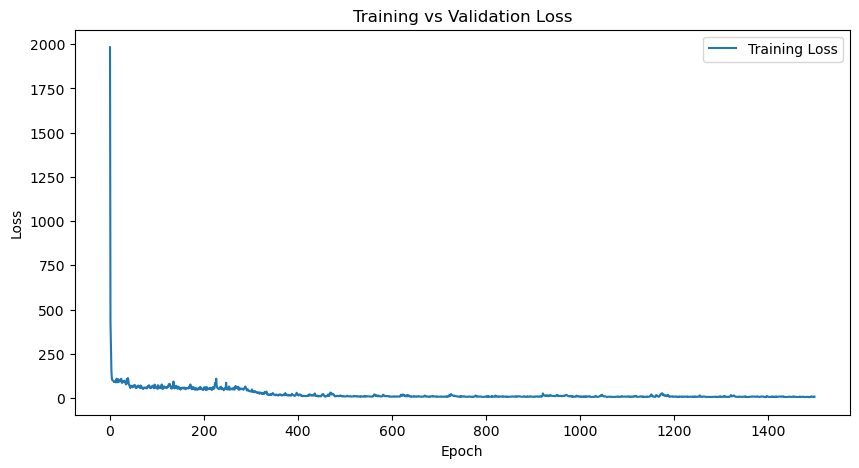

In [51]:
#Now plot:

plt.figure(figsize=(10,5))

plt.plot(train_losses_load, label='Training Loss')
plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()

plt.show()

In [53]:

def evaluate_model(model_load, dataloader, device):

    model_load.eval()

    y_true_load = []
    y_pred_load = []

    with torch.no_grad():

        for inputs, labels in dataloader:

            inputs = inputs.to(device)

            predictions = model_load(inputs).squeeze(1)

            y_true_load.extend(labels.numpy())

            y_pred_load.extend(
                predictions.cpu().numpy()
            )

    y_true_load = np.array(y_true_load)
    y_pred_load = np.array(y_pred_load)


    r2_load = r2_score(y_true_load, y_pred_load)

    mse_load = mean_squared_error(y_true_load, y_pred_load)

    rmse_load = np.sqrt(mse_load)

    mae_load = mean_absolute_error(y_true_load, y_pred_load)

    mape_load = mean_absolute_percentage_error(
        y_true_load,
        y_pred_load
    ) * 100

    evs_load = explained_variance_score(
        y_true_load,
        y_pred_load
    )

    pearson_r_load, _ = pearsonr(
        y_true_load,
        y_pred_load
    )

    rrmse_load = (
        rmse_load / np.mean(y_true_load)
    ) * 100

    return {
        "R2 Score": r2_load,
        "MSE": mse_load,
        "RMSE": rmse_load,
        "MAE": mae_load,
        "MAPE (%)": mape_load,
        "Explained Variance Score": evs_load,
        "Pearson Correlation (R)": pearson_r_load,
        "Relative RMSE (%)": rrmse_load
    }

train_metrics = evaluate_model(
    model_load,
    train_dataloader,
    device
)

test_metrics = evaluate_model(
    model_load,
    testing_dataloader,
    device
)

df_results = pd.DataFrame({
    "Train": train_metrics,
    "Test": test_metrics
})

print(df_results.round(4))

                           Train    Test
R2 Score                  0.9673  0.9508
MSE                       3.5237  7.1457
RMSE                      1.8771  2.6731
MAE                       1.2141  2.0627
MAPE (%)                  2.8993  5.5280
Explained Variance Score  0.9680  0.9524
Pearson Correlation (R)   0.9841  0.9759
Relative RMSE (%)         4.1125  6.0473


In [54]:
def y_trueloadAndy_predload(model, testing_dataloader, device):

    model_load.eval()

    y_true_load = []
    y_pred_load = []

    with torch.no_grad():

        for inputs, labels in testing_dataloader:

            inputs = inputs.to(device)

            predictions = model(inputs).squeeze(1)

            y_true_load.extend(labels.numpy())

            y_pred_load.extend(
                predictions.cpu().numpy()
            )

    y_true_load = np.array(y_true_load)
    y_pred_load = np.array(y_pred_load)

    return y_true_load, y_pred_load



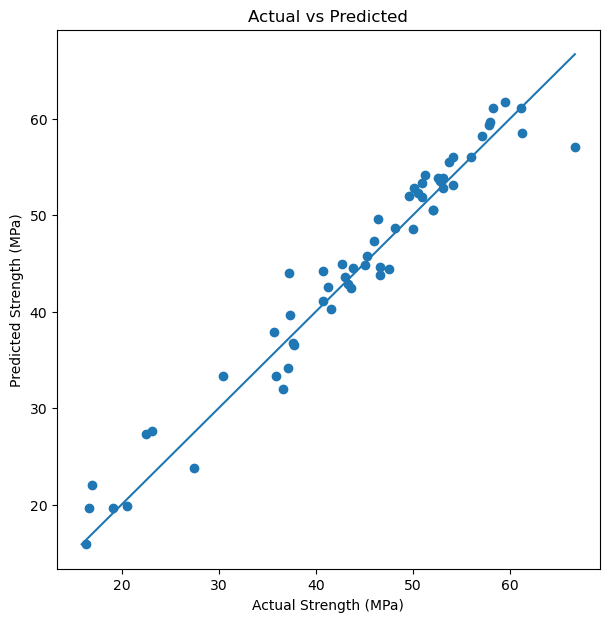

In [55]:
#Actual vs predicted plot with loaded model

y_true_load = y_trueloadAndy_predload( model_load, testing_dataloader, device)[0]
y_pred_load = y_trueloadAndy_predload( model_load, testing_dataloader, device)[1]


plt.figure(figsize=(7,7))

plt.scatter(y_true_load, y_pred_load)

min_val = min(
    min(y_true_load),
    min(y_pred_load)
)

max_val = max(
    max(y_true_load),
    max(y_pred_load)
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val]
)

plt.xlabel("Actual Strength (MPa)")

plt.ylabel("Predicted Strength (MPa)")

plt.title("Actual vs Predicted")

plt.show()